[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sage-ai-group/learn-ml-by-building/blob/main/Lecture%2014%20Transformers/14-Transformers.ipynb)

# Lecture 14: Transformers and Attention

The next word depends on what came before it. How does a transformer make that
context available to its prediction? We'll inspect a small pretrained GPT-2,
reconstruct one attention head, and change sentences to test which information
can affect a token. All model outputs below are computed from pretrained weights;
the short sentences are deliberately chosen examples, not an evaluation dataset.

In [1]:
# @title Colab Setup
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    import subprocess
    repository = Path('/content/learn-ml-by-building')
    if not repository.exists():
        subprocess.run(['git', 'clone', '-q', '--depth', '1',
                        'https://github.com/sage-ai-group/learn-ml-by-building.git', str(repository)], check=True)
    os.chdir(repository / 'Lecture 14 Transformers')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'transformers==4.57.6', 'torch', 'numpy', 'matplotlib'], check=True)
    print('Colab setup complete. Public model weights download on first use.')
else:
    print('Running locally. Public model weights are reused when cached.')

Running locally. Public model weights are reused when cached.


In [2]:
import base64
import html
import io
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
from IPython.display import display
import torch
import transformers
from transformers import GPT2LMHeadModel, GPT2Tokenizer, BertModel, BertTokenizer

torch.set_num_threads(2)
BLUE, CORAL, TEAL, INK = '#3978CB', '#DF7253', '#279489', '#293540'
GRAY = '#E5E9EE'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 12, 'axes.titlesize': 14,
                     'axes.titlepad': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': INK, 'text.color': INK, 'axes.edgecolor': '#B7C1C9',
                     'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white'})
ATTENTION_CMAP = LinearSegmentedColormap.from_list('attention', ['#FFFFFF', BLUE, '#163B67'])
ATTENTION_CMAP.set_bad(GRAY)


def figure_switch(views, label, initial=0):
    """Saved HTML controls with a static PNG fallback, as in Lecture 13."""
    pictures = []
    for name, fig in views:
        buffer = io.BytesIO()
        fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
        pictures.append(base64.b64encode(buffer.getvalue()).decode())
        plt.close(fig)
    options = ''.join(f'<option value="{i}" {"selected" if i == initial else ""}>{html.escape(name)}</option>'
                      for i, (name, _) in enumerate(views))
    images = ''.join(f'<img alt="{html.escape(views[i][0])}" data-frame="{i}" src="data:image/png;base64,{p}" '
                     f'style="width:100%;display:{"block" if i == initial else "none"}"/>' for i, p in enumerate(pictures))
    markup = (f'<div style="max-width:1200px"><label style="font:16px sans-serif">{html.escape(label)}: '
              f'<select style="font:inherit;padding:6px;margin-bottom:10px" onchange="Array.from(this.closest(\'div\').querySelectorAll(\'img[data-frame]\')).forEach((im,i)=>im.style.display=(i===+this.value?\'block\':\'none\'))">'
              f'{options}</select></label>{images}</div>')
    display({'text/html': markup, 'image/png': pictures[initial],
             'text/plain': f'{label}: {views[initial][0]}'}, raw=True)


def attention_map(ax, matrix, labels, title):
    n = len(labels)
    future = np.triu(np.ones((n, n), dtype=bool), 1)
    im = ax.imshow(np.ma.array(matrix, mask=future), cmap=ATTENTION_CMAP, vmin=0, vmax=1)
    ax.set(xticks=range(n), xticklabels=labels, yticks=range(n), yticklabels=labels,
           xlabel='Key token', ylabel='Query token', title=title)
    ax.tick_params(axis='x', rotation=45, labelsize=10)
    ax.tick_params(axis='y', labelsize=10)
    ax.spines[['left', 'bottom']].set_visible(False)
    return im


def relative_change(a, b):
    return (a - b).norm(dim=-1) / ((a.norm(dim=-1) + b.norm(dim=-1)) / 2).clamp_min(1e-12)


tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
model = GPT2LMHeadModel.from_pretrained('gpt2', attn_implementation='eager').eval()


@torch.no_grad()
def inspect(text):
    return model(**tokenizer(text, return_tensors='pt'), output_attentions=True,
                 output_hidden_states=True, use_cache=False)


print(f'GPT-2: {model.config.n_layer} blocks, {model.config.n_head} heads per block, '
      f'{model.config.n_embd} hidden coordinates. Transformers {transformers.__version__}; CPU inference.')

GPT-2: 12 blocks, 12 heads per block, 768 hidden coordinates. Transformers 4.57.6; CPU inference.


## 1. What Is the Model Predicting?

Both prompts end with **the**. Which words would you expect next?
GPT-2 assigns probabilities to 50,257 possible tokens. A token may be a word,
a word fragment, punctuation, or a space followed by a word. The bars show the
five most likely next tokens, with their original probabilities—not renormalized
to sum to one. The spaces inside the quotes are part of the tokens.

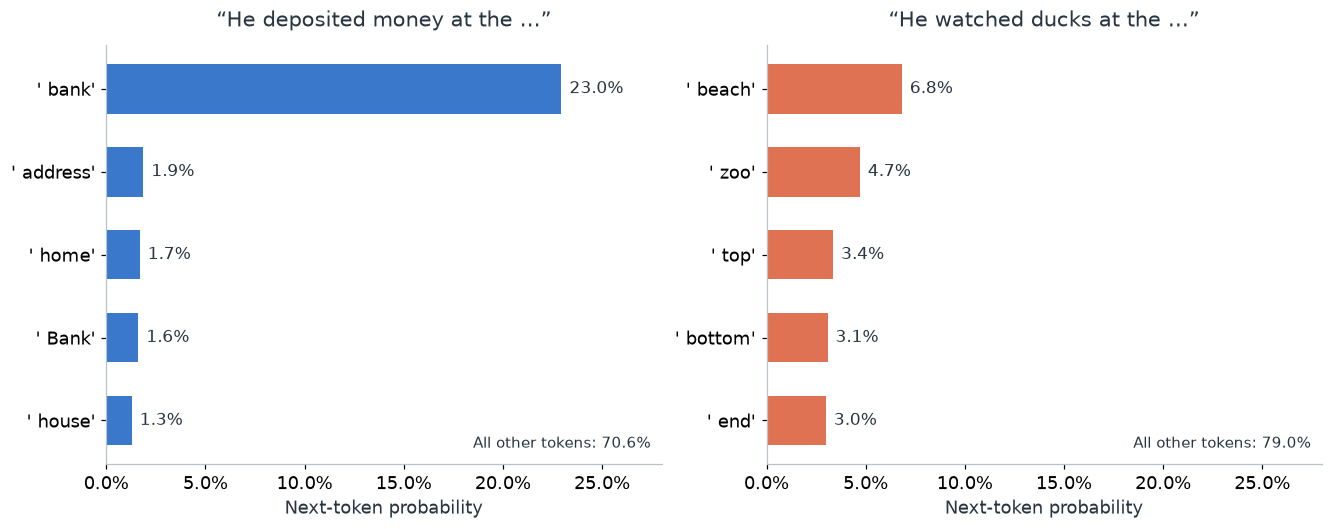

In [3]:
prefixes = ['He deposited money at the', 'He watched ducks at the']
prefix_outputs = [inspect(text) for text in prefixes]
next_probabilities = [out.logits[0, -1].softmax(dim=-1) for out in prefix_outputs]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), sharex=True, layout='constrained')
for ax, text, probabilities, color in zip(axes, prefixes, next_probabilities, [BLUE, CORAL]):
    values, ids = probabilities.topk(5)
    labels = [repr(tokenizer.decode([i])) for i in ids.tolist()]
    ax.barh(range(5), values.numpy(), color=color, height=.6)
    ax.set(yticks=range(5), yticklabels=labels, xlim=(0, .28),
           xlabel='Next-token probability', title=f'“{text} …”')
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    for y, probability in enumerate(values.tolist()):
        ax.text(probability + .004, y, f'{probability:.1%}', va='center', fontsize=11)
    ax.text(.98, .04, f'All other tokens: {1 - values.sum().item():.1%}',
            transform=ax.transAxes, ha='right', fontsize=10, color=INK)
plt.show()

`logits[0, -1]` contains the vocabulary scores at the last input position;
`softmax` turns them into the distribution for the **next** token. These are
continuation probabilities, not probabilities that an answer is factually correct.
The model favors different continuations even though the last token is identical.
What changed inside its representation?

GPT-2 starts with **token embeddings + position embeddings**. Each of its 12 blocks
mixes information across positions using attention, then applies a feed-forward
network to each position. Both operations have residual connections and layer
normalization. A final normalization and linear vocabulary readout produce the
logits. The feed-forward network connects directly to our previous lecture;
attention supplies the interaction between tokens.

## 2. How Does One Token Use the Others?

Let's append **bank** to the first prompt and inspect one actual head. A learned
projection makes queries $Q$, keys $K$, and values $V$. Queries and keys determine
the weights; values supply the vectors being combined:

$$A=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad C=AV.$$

Softmax acts across each row. The causal mask $M$ is zero for the current and
earlier positions, and $-\infty$ for future positions. Each row of $C$ is one
64-dimensional head output. The block combines all 12 heads afterward.

In [4]:
sentence = prefixes[0] + ' bank'
layer, head = 5, 2  # Zero-indexed; a relatively distributed head in this example.
block = model.transformer.h[layer]
captured = {}


def capture_head_output(module, args):
    captured['joined_heads'] = args[0].detach()


handle = block.attn.c_proj.register_forward_pre_hook(capture_head_output)
try:
    sentence_output = inspect(sentence)
finally:
    handle.remove()
token_ids = tokenizer.encode(sentence)
token_labels = [f'{i} {tokenizer.decode([token]).strip()}' for i, token in enumerate(token_ids)]
n_tokens, d_k = len(token_ids), model.config.n_embd // model.config.n_head
with torch.no_grad():
    head_input = block.ln_1(sentence_output.hidden_states[layer])
    projected = block.attn.c_attn(head_input).split(model.config.n_embd, dim=-1)
    Q, K, V = [part.reshape(n_tokens, model.config.n_head, d_k)[:, head] for part in projected]

scores = Q @ K.T / math.sqrt(d_k)
future_mask = torch.ones_like(scores, dtype=torch.bool).triu(diagonal=1)
weights = scores.masked_fill(future_mask, -torch.inf).softmax(dim=-1)
context = weights @ V

actual_weights = sentence_output.attentions[layer][0, head]
actual_context = captured['joined_heads'].reshape(n_tokens, model.config.n_head, d_k)[:, head]
torch.testing.assert_close(weights, actual_weights, atol=2e-6, rtol=2e-5)
torch.testing.assert_close(context, actual_context, atol=2e-6, rtol=2e-5)
assert weights[future_mask].abs().max().item() == 0
torch.testing.assert_close(weights.sum(-1), torch.ones(n_tokens))
reconstruction_error = (context - actual_context).abs().max().item()
print(f'Attention rows sum to 1; future weights are 0. '
      f'Maximum head-output reconstruction error: {reconstruction_error:.2e}.')

Attention rows sum to 1; future weights are 0. Maximum head-output reconstruction error: 0.00e+00.


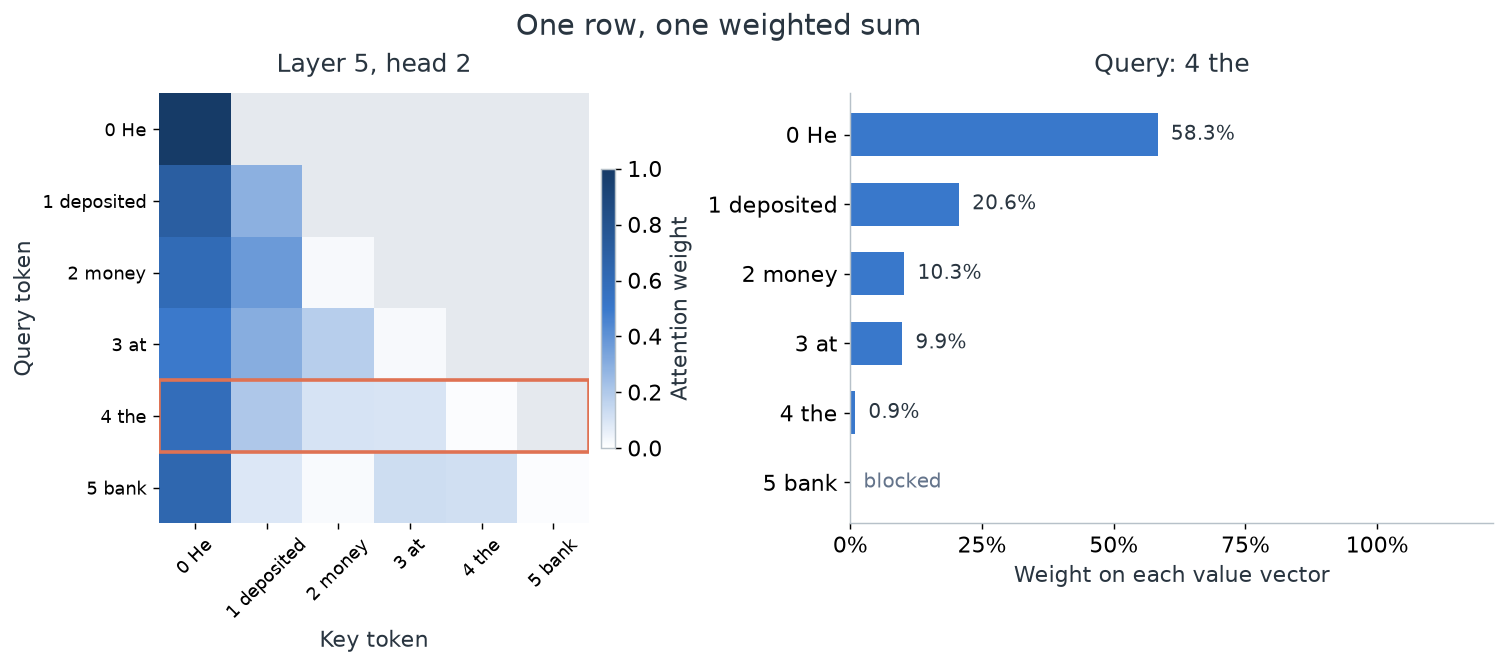

In [5]:
query_views = []
for query in range(n_tokens):
    fig, (matrix_ax, row_ax) = plt.subplots(1, 2, figsize=(12, 5),
                                          gridspec_kw={'width_ratios': [1, 1.1]}, layout='constrained')
    im = attention_map(matrix_ax, weights.numpy(), token_labels, f'Layer {layer}, head {head}')
    matrix_ax.add_patch(Rectangle((-.5, query-.5), n_tokens, 1, fill=False, edgecolor=CORAL, lw=2))
    bars = weights[query].numpy()
    row_ax.barh(range(n_tokens), bars, color=[BLUE if j <= query else GRAY for j in range(n_tokens)], height=.62)
    for j, value in enumerate(bars):
        row_ax.text(value+.025, j, 'blocked' if j > query else f'{value:.1%}', va='center', fontsize=11,
                    color=INK if j <= query else '#64748B')
    row_ax.set(yticks=range(n_tokens), yticklabels=token_labels, xlim=(0, 1.22),
               xlabel='Weight on each value vector', title=f'Query: {token_labels[query]}')
    row_ax.invert_yaxis()
    row_ax.set_xticks([0, .25, .5, .75, 1])
    row_ax.xaxis.set_major_formatter(PercentFormatter(1))
    fig.colorbar(im, ax=matrix_ax, shrink=.65, pad=.02, label='Attention weight')
    fig.suptitle('One row, one weighted sum', fontsize=16)
    query_views.append((token_labels[query], fig))
figure_switch(query_views, 'Query token', initial=4)

The outlined row and the bars contain the same numbers. Gray cells are unavailable
future positions; pale allowed cells simply receive little weight. `weights @ V`
reconstructs the model's head output, so the heatmap has a precise computational
meaning. A large weight alone does not establish how important that token is to
the final prediction: value vectors, other heads, residual paths, and later
transformations also matter.

## 3. Which Words Can Affect This Representation?

Compare **“The bank was closed”** with **“The bank was flooded.”** Only the final
word changes. We inspect **bank**, which comes before it. Would its representation
change in GPT-2? What about a bidirectional model such as BERT?

At each stage we compare the complete hidden vectors, without a PCA projection:
$\Delta=\|h_A-h_B\|_2/[\tfrac12(\|h_A\|_2+\|h_B\|_2)]$.
Zero means identical vectors. This is a within-model change measure, not a
probability or a measure of which model understands the sentence better.

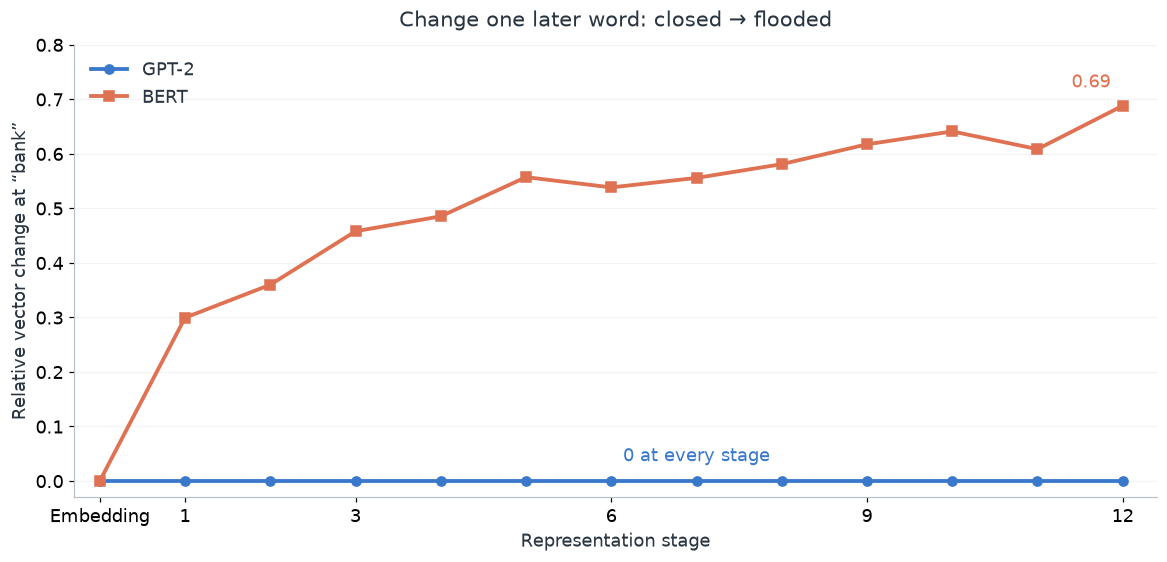

In [6]:
suffix_texts = ['The bank was closed', 'The bank was flooded']
suffix_gpt = [inspect(text) for text in suffix_texts]
bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased', attn_implementation='eager').eval()
with torch.no_grad():
    suffix_bert = [bert(**bert_tokenizer(text, return_tensors='pt'), output_hidden_states=True)
                   for text in suffix_texts]
gpt_bank = tokenizer.encode(suffix_texts[0]).index(tokenizer.encode(' bank')[0])
bert_bank = bert_tokenizer.encode(suffix_texts[0]).index(bert_tokenizer.convert_tokens_to_ids('bank'))
suffix_changes = {}
for name, outputs, position in [('GPT-2', suffix_gpt, gpt_bank), ('BERT', suffix_bert, bert_bank)]:
    a, b = [torch.stack(out.hidden_states)[:, 0, position] for out in outputs]
    suffix_changes[name] = relative_change(a, b).numpy()
assert np.max(suffix_changes['GPT-2']) == 0
assert suffix_changes['BERT'][0] == 0 and suffix_changes['BERT'][-1] > .1

fig, ax = plt.subplots(figsize=(10.5, 5), layout='constrained')
for name, color, marker in [('GPT-2', BLUE, 'o'), ('BERT', CORAL, 's')]:
    ax.plot(range(13), suffix_changes[name], color=color, marker=marker, ms=6, lw=2.5, label=name)
ax.set(xlabel='Representation stage', ylabel='Relative vector change at “bank”',
       xticks=[0, 1, 3, 6, 9, 12], xticklabels=['Embedding', '1', '3', '6', '9', '12'],
       ylim=(-.03, .8), xlim=(-.3, 12.4), title='Change one later word: closed → flooded')
ax.grid(axis='y', alpha=.15)
ax.legend(loc='upper left', frameon=False)
ax.annotate(f'{suffix_changes["BERT"][-1]:.2f}', (12, suffix_changes['BERT'][-1]),
            xytext=(-8, 12), textcoords='offset points', ha='right', color=CORAL)
ax.annotate('0 at every stage', (7, 0), xytext=(0, 13), textcoords='offset points', ha='center', color=BLUE)
plt.show()

GPT-2 cannot use the changed word when forming its earlier **bank** representation.
BERT can attend to both sides, so the later word can affect it. The unchanged
starting vectors also check that the target token and its position stayed fixed.
GPT-2's final reported state includes its final layer normalization; the comparison
always uses the same stage within each model.

Causal attention supports left-to-right next-token prediction. Standard BERT is
pretrained to recover masked tokens using both sides. These are differences in
information access and training objective, not a division between models that
can “generate” and models that can “understand.”

## 4. Do All Heads Behave the Same Way?

Return to **“He deposited money at the bank.”** These three layer/head pairs were
selected because their patterns are easy to compare; they are not a random sample
of the 144 heads. Where does each query put most of its weight?

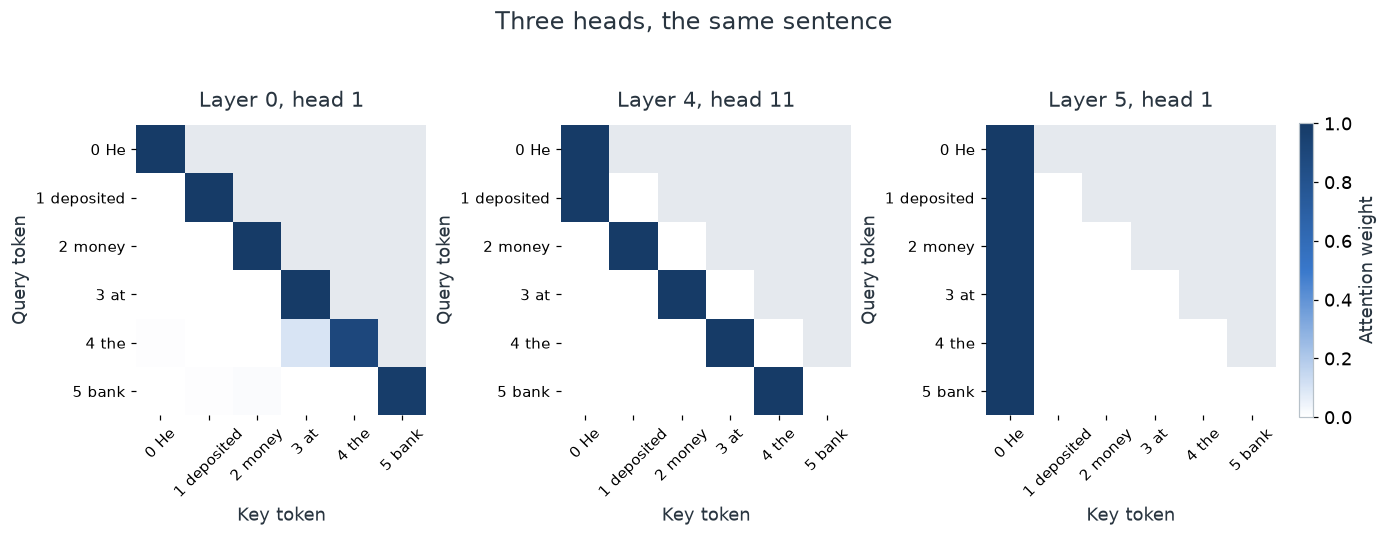

In [7]:
head_examples = [(0, 1), (4, 11), (5, 1)]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.8), layout='constrained')
for ax, (selected_layer, selected_head) in zip(axes, head_examples):
    matrix = sentence_output.attentions[selected_layer][0, selected_head].numpy()
    im = attention_map(ax, matrix, token_labels, f'Layer {selected_layer}, head {selected_head}')
fig.colorbar(im, ax=axes, shrink=.65, pad=.02, label='Attention weight')
fig.suptitle('Three heads, the same sentence', fontsize=16)
plt.show()

The diagonal follows the current token; the stripe just below it follows the
preceding token; the first column repeatedly selects the first token. These
are selected examples of positional behavior, not universal roles such as “the grammar head”
or “the meaning head.” Heads in different layers have separate learned parameters,
even when their index happens to be the same.

## 5. How Does Context Change the Same Word?

Now change the words **before** the target. Both prompts from the opening receive
the same final token:

“He deposited money at the **bank**.”

“He watched ducks at the **bank**.”

We omit the final period when passing the prompts to GPT-2. **bank** has the same
token ID and position in both, so its token-plus-position embedding is identical.
Does that remain true at the final representation? Does its next-token distribution
change too? The left panel uses the same relative-change measure as before; the
right shows the five tokens with the largest absolute probability changes.

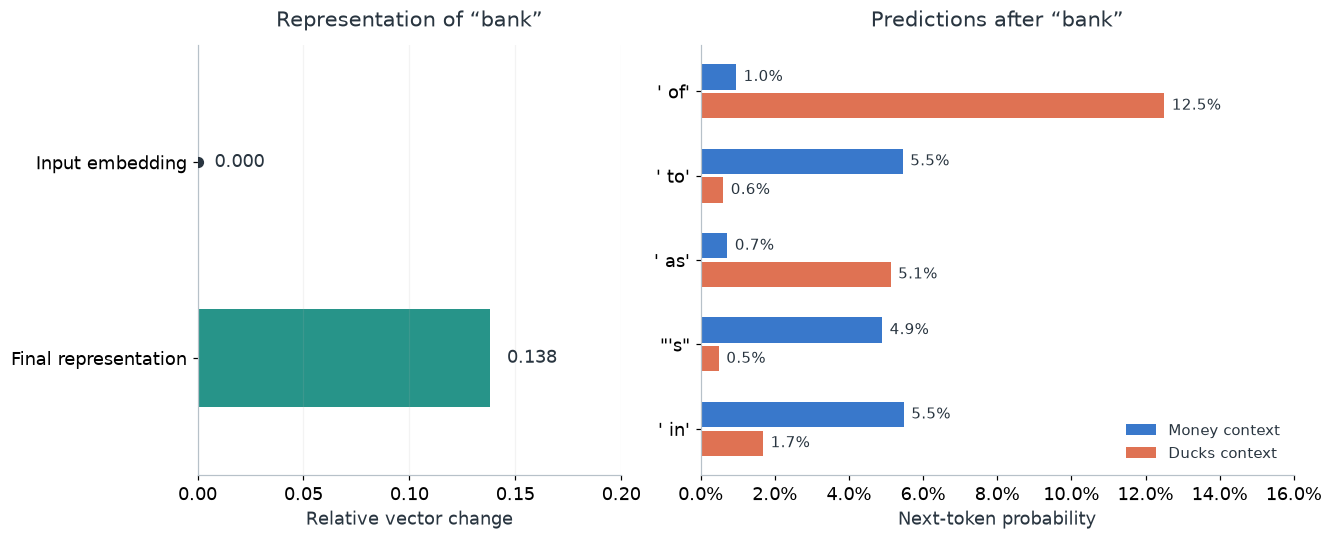

In [8]:
context_texts = [prefix + ' bank' for prefix in prefixes]
context_ids = [tokenizer.encode(text) for text in context_texts]
assert len(context_ids[0]) == len(context_ids[1]) and context_ids[0][-1] == context_ids[1][-1]
context_outputs = [sentence_output, inspect(context_texts[1])]
context_changes = [relative_change(*[out.hidden_states[stage][0, -1] for out in context_outputs]).item()
                   for stage in [0, -1]]
assert context_changes[0] == 0 and context_changes[1] > .05
context_probs = torch.stack([out.logits[0, -1].softmax(-1) for out in context_outputs])
changed_ids = (context_probs[1] - context_probs[0]).abs().topk(5).indices

fig, (state_ax, prediction_ax) = plt.subplots(1, 2, figsize=(12, 4.8),
                                             gridspec_kw={'width_ratios': [1, 1.4]}, layout='constrained')
state_ax.barh([0, 1], context_changes, color=[GRAY, TEAL], height=.5)
state_ax.scatter([0], [0], color=INK, s=40, zorder=3)
for y, value in enumerate(context_changes):
    state_ax.text(value+.008, y, f'{value:.3f}', va='center', fontsize=12)
state_ax.set(yticks=[0, 1], yticklabels=['Input embedding', 'Final representation'],
             xlim=(0, .20), ylim=(1.6, -.6), xlabel='Relative vector change', title='Representation of “bank”')
state_ax.grid(axis='x', alpha=.15)
for i, (label, color) in enumerate([('Money context', BLUE), ('Ducks context', CORAL)]):
    values = context_probs[i, changed_ids].numpy()
    positions = np.arange(5) + (i-.5)*.34
    prediction_ax.barh(positions, values, height=.3, color=color, label=label)
    for y, value in zip(positions, values):
        prediction_ax.text(value+.002, y, f'{value:.1%}', va='center', fontsize=10)
prediction_ax.set(yticks=range(5), yticklabels=[repr(tokenizer.decode([i])) for i in changed_ids.tolist()],
                  xlim=(0, .16), xlabel='Next-token probability', title='Predictions after “bank”')
prediction_ax.invert_yaxis()
prediction_ax.xaxis.set_major_formatter(PercentFormatter(1))
prediction_ax.legend(loc='lower right', frameon=False, fontsize=10)
plt.show()

The model starts with identical target embeddings but ends with different
representations and predictions. Earlier context reached **bank** through the
transformer. That is the result this experiment establishes. The different vectors
alone do not prove that a coordinate means “finance” or “river,” and the selected
probability changes do not measure overall language-model quality. Position was
controlled here; two occurrences at different positions would already differ
before attention, because GPT-2 adds learned position embeddings.

## What to Take Away

A transformer builds context-dependent representations by mixing value vectors
with learned attention weights and transforming the result through its blocks.
The mask determines which positions can contribute: changing a future word leaves
GPT-2's earlier representation unchanged, while changing earlier context can alter
both that representation and its next-token prediction. Attention maps reveal
these computations, but interpreting their linguistic role or causal importance
takes more evidence than a bright square or a separated pair of points.

Sources: [GPT-2 model and implementation](https://huggingface.co/docs/transformers/v4.57.1/en/model_doc/gpt2),
[BERT](https://aclanthology.org/N19-1423/),
[What Does BERT Look At?](https://aclanthology.org/W19-4828/), and the discussion of
[attention and explanation](https://aclanthology.org/N19-1357/).